<a href="https://colab.research.google.com/github/Semenovaanzhelika31/intro-ai/blob/main/lab3_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 3

## Задание
Решите пожалуйста следующую задачу.

1. Примените методы снижения размерности (до двумерного представления
n_components=2) перечисленные ниже для данных находящихся пo
[ссылке](https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view). Здесь - метка (учитель) является столбец / атрибут - `outcome`. Предоставьте результаты, используя следующие ядерные функции:
- PCA
- LDA
- TruncatedSVD
- Kernel PCA (перебрав все ядерные функции - ('linear', 'poly', 'rbf', sigmoid',
'cosine', 'precomputed')

## Загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
! gdown --fuzzy 'https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view'

Downloading...
From: https://drive.google.com/uc?id=1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec
To: /content/diabetes.csv
100% 23.1k/23.1k [00:00<00:00, 44.4MB/s]


In [3]:
df = pd.read_csv('/content/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


##  О датасете
[Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database/data)

Этот набор данных взят из Национального института диабета, заболеваний органов пищеварения и почек (NIDDK). Целью набора данных является диагностическое предсказание наличия у пациента диабета на основе определенных диагностических измерений, включенных в набор данных. На выбор этих экземпляров из более крупной базы данных было наложено несколько ограничений. В частности, все пациенты здесь — женщины не моложе 21 года, родом из индейцев Пима.

Наборы данных состоят из нескольких переменных медицинских предикторов и одной целевой переменной `Outcome`. Переменные-предикторы включают количество беременностей, которые были у пациентки, её индекс массы тела `BMI`, уровень инсулина, возраст и так далее. Всего в датасете 9 переменных:
- `Pregnancies` - количество беременностей;
- `Glucose` - концентрация глюкозы в плазме через 2 часа при пероральном тесте на толерантность к глюкозе;
- `BloodPressure` - диастолическое артериальное давление (мм рт. ст.);
- `SkinThickness` - толщина кожной складки трицепса (мм);
- `Insulin` - 2-часовой сывороточный инсулин (мкЕд/мл);
- `BMI` - Индекс массы тела (вес в кг/(рост в м)^2);
- `DiabetesPedigreeFunction` - функция оценки вероятности диабета на основе семейного анамнеза;
- `Age` - возраст (лет);
- `Outcome` - целевая переменная (0 или 1) 268 из 768 — 1 (больны), остальные — 0 (здоровы).



In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [6]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics.pairwise import rbf_kernel
import matplotlib.pyplot as plt

cols_to_fix = ['SkinThickness', 'BMI', 'Insulin']
df[cols_to_fix] = df[cols_to_fix].replace(0, np.nan)
df[cols_to_fix] = df[cols_to_fix].fillna(df[cols_to_fix].median())

X = df.drop('Outcome', axis=1)
y = df['Outcome']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

def plot_2d(X_transformed, title):
    plt.figure(figsize=(7, 5))
    scatter = plt.scatter(X_transformed[:, 0], X_transformed[:, 1], c=y, cmap='coolwarm', alpha=0.7, edgecolor='k')
    plt.title(title)
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.colorbar(scatter, label='Outcome')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

## Метод PCA

Объясненная дисперсия компонент: [0.27232043 0.1854825 ]
Суммарная объясненная дисперсия: 0.4578



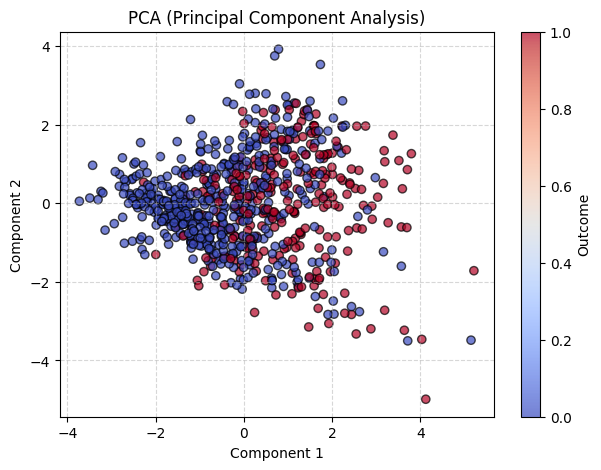

In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"Объясненная дисперсия компонент: {pca.explained_variance_ratio_}")
print(f"Суммарная объясненная дисперсия: {sum(pca.explained_variance_ratio_):.4f}\n")

plot_2d(X_pca, 'PCA (Principal Component Analysis)')

## Метод LDA

Объясненная дисперсия компонент LDA: [1.]
Суммарная объясненная дисперсия: 1.0000



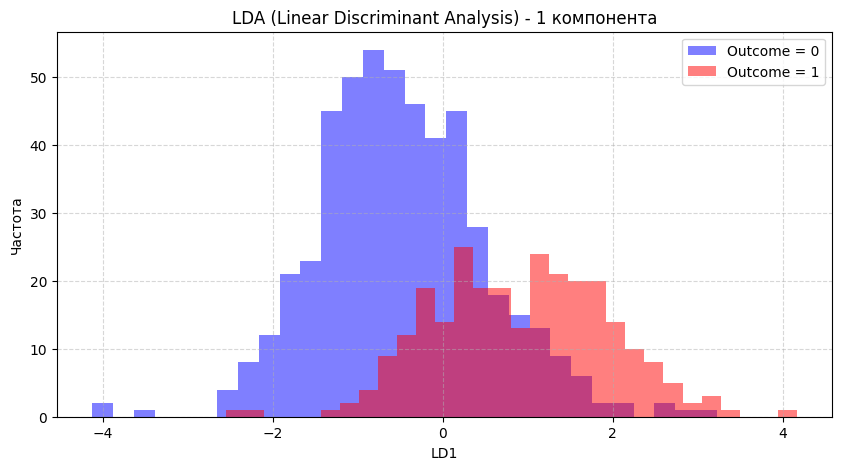

In [11]:
lda = LDA(n_components=1)
X_lda = lda.fit_transform(X_scaled, y)

print(f"Объясненная дисперсия компонент LDA: {lda.explained_variance_ratio_}")
print(f"Суммарная объясненная дисперсия: {sum(lda.explained_variance_ratio_):.4f}\n")

plt.figure(figsize=(10, 5))
plt.hist(X_lda[y == 0], bins=30, alpha=0.5, label='Outcome = 0', color='blue')
plt.hist(X_lda[y == 1], bins=30, alpha=0.5, label='Outcome = 1', color='red')
plt.title('LDA (Linear Discriminant Analysis) - 1 компонента')
plt.xlabel('LD1')
plt.ylabel('Частота')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Метод TruncatedSVD

Объясненная дисперсия компонент: [0.27232043 0.1854825 ]
Суммарная объясненная дисперсия: 0.4578



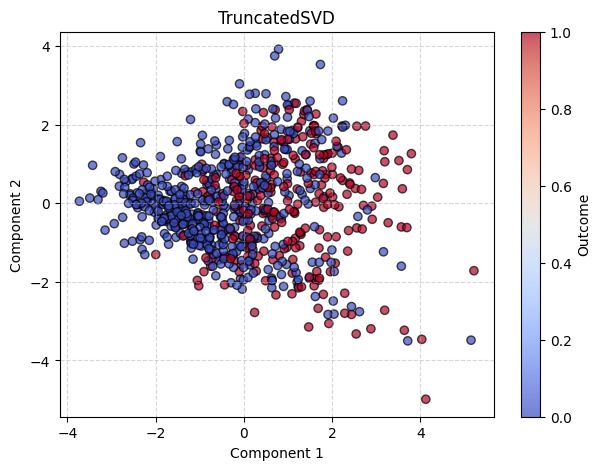

In [12]:
svd = TruncatedSVD(n_components=2)
X_svd = svd.fit_transform(X_scaled)

print(f"Объясненная дисперсия компонент: {svd.explained_variance_ratio_}")
print(f"Суммарная объясненная дисперсия: {sum(svd.explained_variance_ratio_):.4f}\n")

plot_2d(X_svd, 'TruncatedSVD')

## Метод Kernel PCA

###  Ядерная функция `linear`

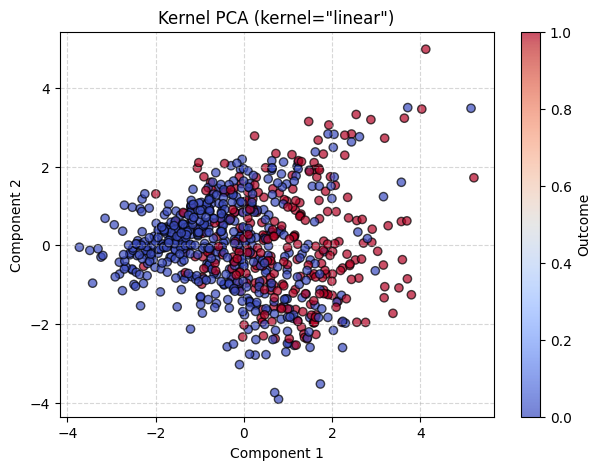

In [16]:
kpca_lin = KernelPCA(n_components=2, kernel='linear')
X_kpca_lin = kpca_lin.fit_transform(X_scaled)
plot_2d(X_kpca_lin, 'Kernel PCA (kernel="linear")')

###  Ядерная функция `poly`

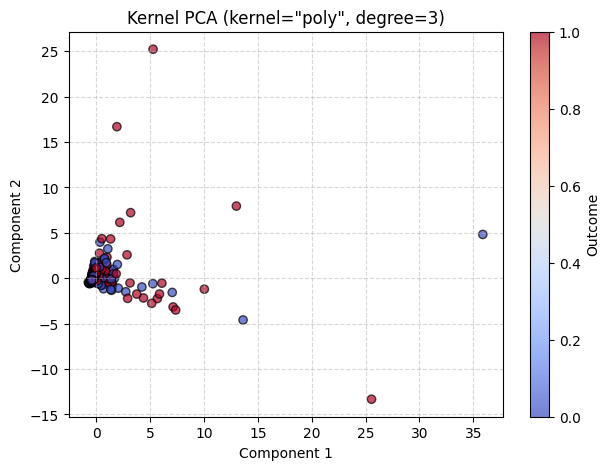

In [17]:
kpca_poly = KernelPCA(n_components=2, kernel='poly', degree=3)
X_kpca_poly = kpca_poly.fit_transform(X_scaled)
plot_2d(X_kpca_poly, 'Kernel PCA (kernel="poly", degree=3)')

###  Ядерная функция `rbf`

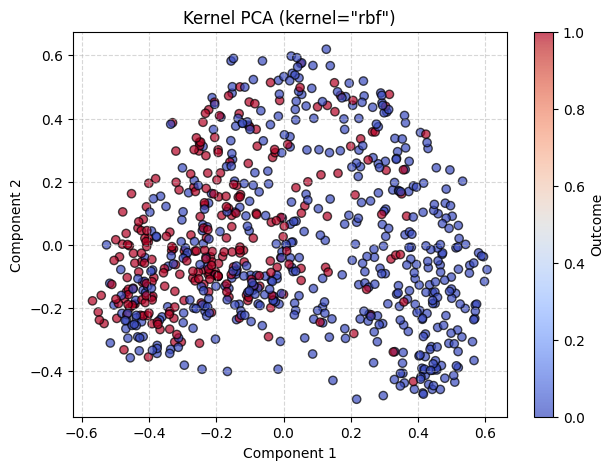

In [21]:
gamma_rbf = 1.0 / (X_scaled.shape[1] * X_scaled.var())

kpca_rbf = KernelPCA(n_components=2, kernel='rbf', gamma=gamma_rbf)
X_kpca_rbf = kpca_rbf.fit_transform(X_scaled)
plot_2d(X_kpca_rbf, 'Kernel PCA (kernel="rbf")')

###  Ядерная функция `sigmoid`

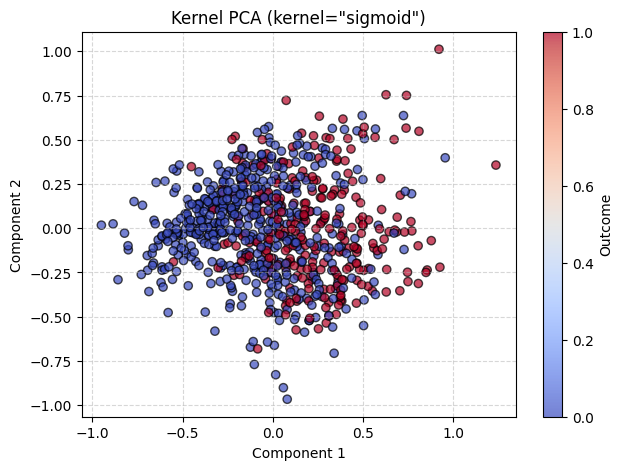

In [22]:
gamma_sig = 1.0 / (X_scaled.shape[1] * X_scaled.var())

kpca_sig = KernelPCA(n_components=2, kernel='sigmoid', gamma=gamma_sig, coef0=1)
X_kpca_sig = kpca_sig.fit_transform(X_scaled)
plot_2d(X_kpca_sig, 'Kernel PCA (kernel="sigmoid")')

###  Ядерная функция `cosine`

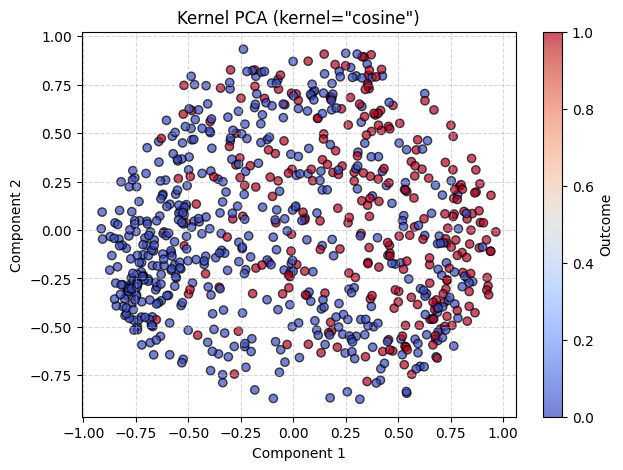

In [23]:
kpca_cos = KernelPCA(n_components=2, kernel='cosine')
X_kpca_cos = kpca_cos.fit_transform(X_scaled)
plot_2d(X_kpca_cos, 'Kernel PCA (kernel="cosine")')

###  Ядерная функция `precomputed`

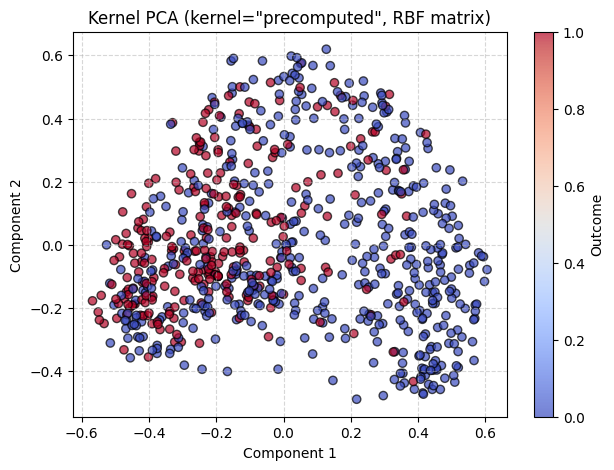

In [25]:
from sklearn.metrics.pairwise import rbf_kernel
K_matrix = rbf_kernel(X_scaled, gamma=gamma_rbf)

kpca_pre = KernelPCA(n_components=2, kernel='precomputed')
X_kpca_pre = kpca_pre.fit_transform(K_matrix)
plot_2d(X_kpca_pre, 'Kernel PCA (kernel="precomputed", RBF matrix)')